## Imports



In [556]:
import matplotlib.pyplot as plt
import numpy as np
import photonforge as pf
import tidy3d as td
from scipy.constants import atomic_mass, elementary_charge
from scipy.integrate import cumulative_trapezoid

# We raise the Tidy3D logging level to reduce output noise from the solve
# below. Warnings can flag real problems, so only suppress them once you have
# confirmed they are not relevant to your case.
td.config.logging.level = "ERROR"


## Parameters:


find everything in terms of these:

first test: in $$\Psi(\mathbf{r}) = \frac{q^2 \lvert \mathbf{E}_{RF}(\mathbf{r}) \rvert^2}{4 m \Omega^2},$$
Omega is equal to  $\Omega = 2\pi f_{RF}$
dumb case lowering Omega == higher psudopotential
assuming lowest bound and graphing in desmos for the height function




intuitivley lower height = deeper well (I think theres no proof)
so I find bounds for each to its lowest thats allowed and rf drive to the lowest thats allowed

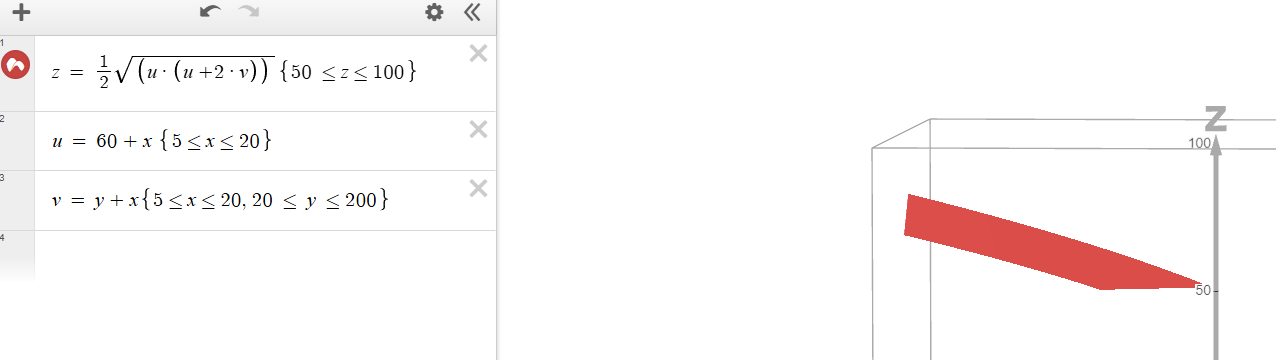

assuming lowest allowed height we get these lines with these points 

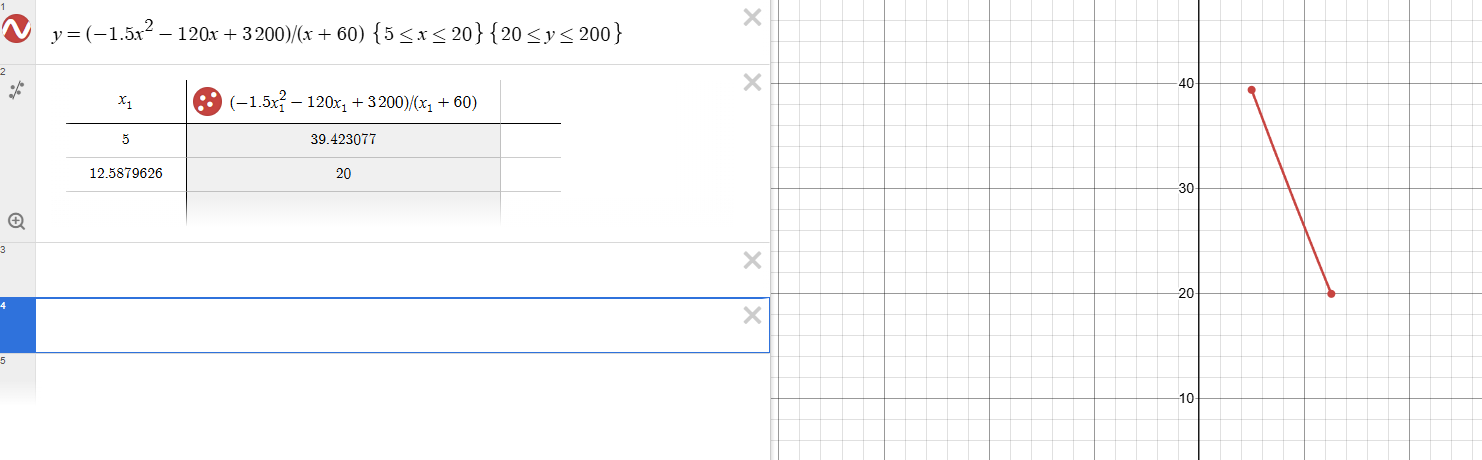

testing them shows:
for rf_width = 39.423007
gap = 5
FAIL

for rf_width = 20
gap = 12.5879626
FAIL

next steps analyze matheiu parimeter since thats what caused both to fail
$$q_M = \frac{2\sqrt{2}\,\omega}{\Omega}.$$
We have now learned that simply shrinking omega ${\Omega}$ is suboptimal.

${\omega}$ is $$\omega = \sqrt{\frac{1}{m} \frac{\partial^2 \Psi}{\partial r^2}}.$$

Using the porportionality laws given in the starting document:
$$\Psi \propto \frac{V_{RF}^2}{\Omega^2}, \qquad \omega \propto \frac{V_{RF}}{\Omega}, \qquad q_M \propto \frac{V_{RF}}{\Omega^2}.$$

we should find a ${\Omega}$ that can just barley fit for $ q_M <= .4$

alternativly We found in [1] how for a given height, the ration between rf width and speration shoulkd be 3.68 for the strongest geometry 

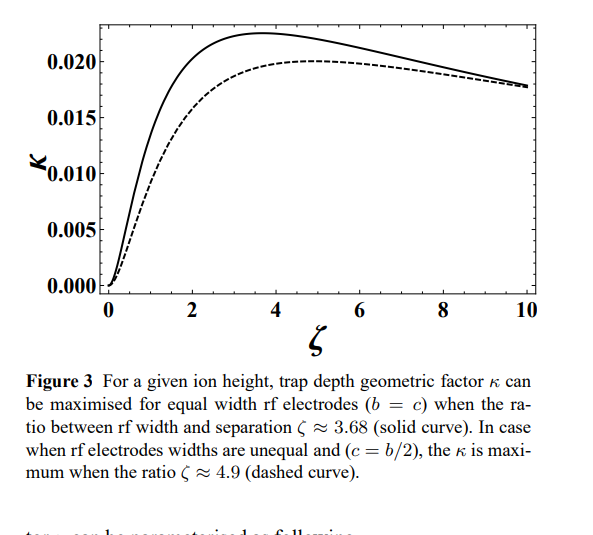



using the previous desmos graph we can get

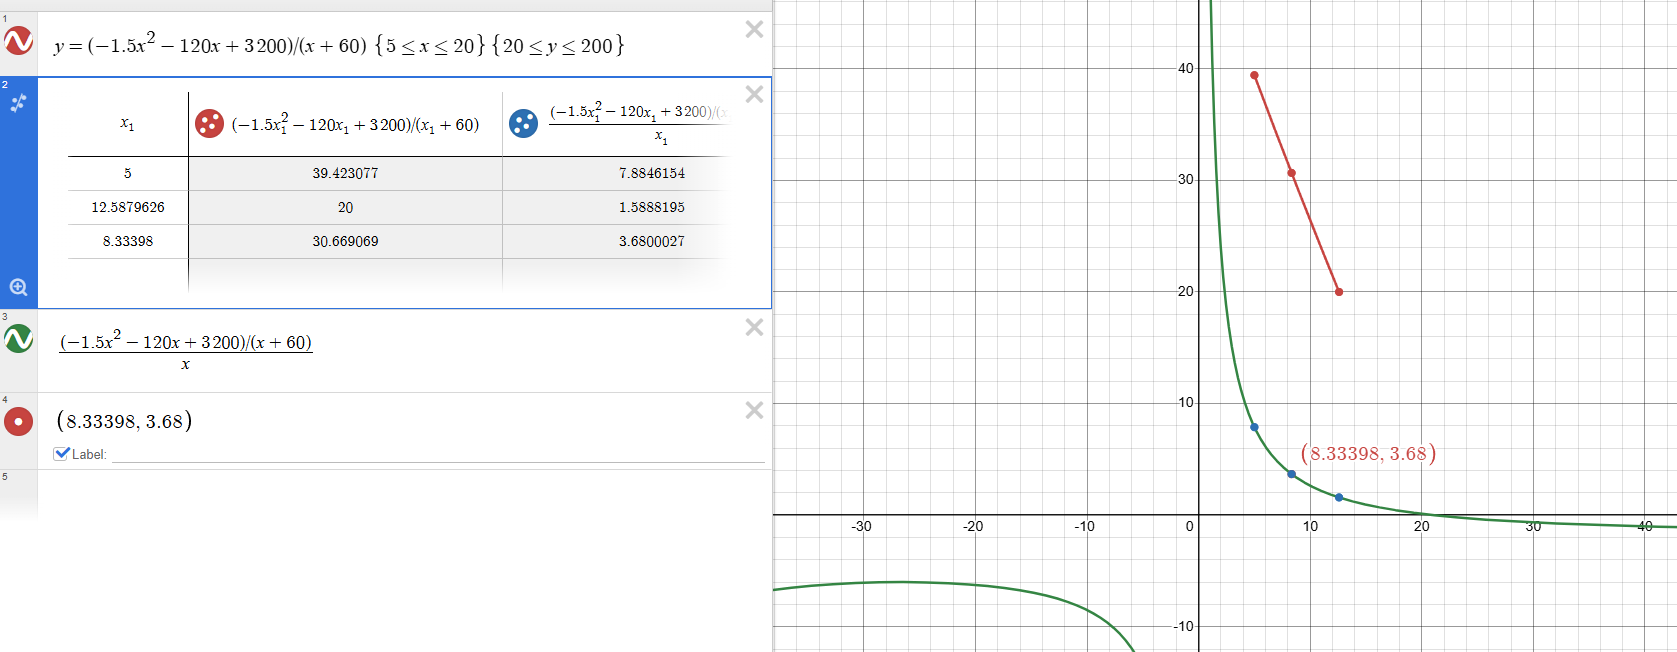

testing those values still yeild a faliure but now we know the ratio between rf_width and gap should be 3.68

I found this equation in this paper [2] 
$$q=2\sqrt{2}\frac{f_{sec}}{f_{rf}}=\frac{2\epsilon QV_{rf}}{mh^{2}(2\pi f_{rf})^{2}},$$
which shows to minimize q we should actually have a larger height if possible so we can just change the height graph we had earlier howver we cannot get a maximum value in the geometry for height as 100 micro m as shown
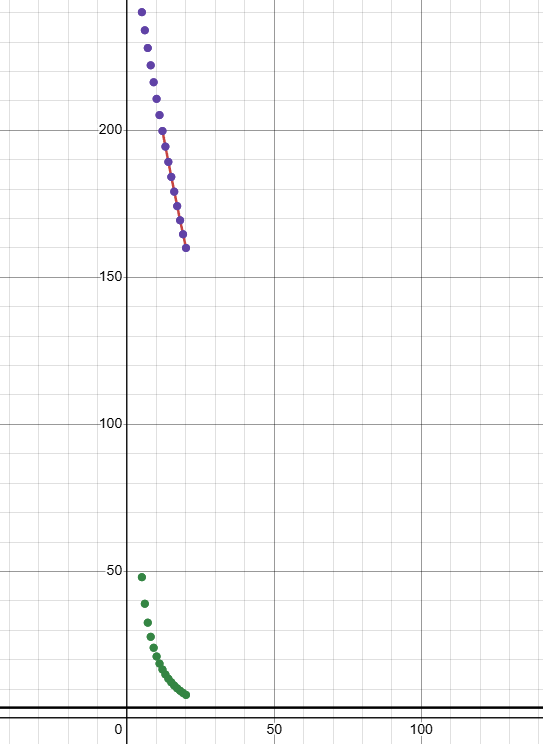
using this desmos graph that replaces y with 3.68x due to the ratio stated before we find that the maximum height that allows for this optimized geometry is 73.10266 before the graph is outside of the bounds. this height allows for a large H while stil maintianing the opimal geometry.


current best numbers:
```
Width of each RF electrode, allowed range 20 to 200 (μm)
rf_width = 73.6

# Gap between neighbouring electrodes, allowed range 5 to 20 (μm)
gap = 20

# Peak RF voltage on the RF electrodes, allowed range 10 to 100 (V)
v_rf = 100

# RF drive frequency, allowed range 10e6 to 60e6 (Hz)
f_rf = 40.875e6
```

rf width and gap was found with the equation for the height and the ratio of 3.68. 
We got lucky and acheived a ratio for a matheiu parameter of exactly 0.4 that being $ 64/(32.7*10^6)^2$ for volts over frequency, could be some geometric changes that could influence the results to be more efficient.


just realized that ive been interpreting the ratio wrong. now since the actual distance between both rf electrode actually matches the now exact ratio of 3.68

```
# Width of each RF electrode, allowed range 20 to 200 (μm)
rf_width = 200

# Gap between neighbouring electrodes, allowed range 5 to 20 (μm)
gap = 5

# Peak RF voltage on the RF electrodes, allowed range 10 to 100 (V)
v_rf = 100

# RF drive frequency, allowed range 10e6 to 60e6 (Hz)
f_rf = 40.6e6

# Width of the central ground electrode
center_width = 44.348
```
Score: 150.4 meV at 100 V
meV per voltage: 1.5041259527225197


In [557]:
# Width of each RF electrode, allowed range 20 to 200 (μm)
rf_width = 200

# Gap between neighbouring electrodes, allowed range 5 to 20 (μm)
gap = 5

# Peak RF voltage on the RF electrodes, allowed range 10 to 100 (V)
v_rf = 100

# RF drive frequency, allowed range 10e6 to 60e6 (Hz)
f_rf = 40.5823859e6

# Width of the central ground electrode
center_width = 44.348

## constants + check for height 


In [558]:

metal_thickness = 2.0  # Thickness of the electrodes (μm)
substrate_thickness = 500.0  # Thickness of the fused-silica substrate (μm)
silica_permittivity = 3.8  # Relative permittivity of fused silica

ion_mass = 40 * atomic_mass  # Mass of a 40Ca+ ion (kg)
ion_charge = elementary_charge  # Charge of a 40Ca+ ion (C)

# Effective electrode widths of the gapless model (μm)
a_eff = center_width + gap
b_eff = rf_width + gap

# Ion height from the closed-form gapless model (μm)
h_estimate = 0.5 * np.sqrt(a_eff * (a_eff + 2 * b_eff))
print(f"Estimated ion height: {h_estimate:.3f} μm")


Estimated ion height: 75.279 μm


## setting up sim env in tidy 3d

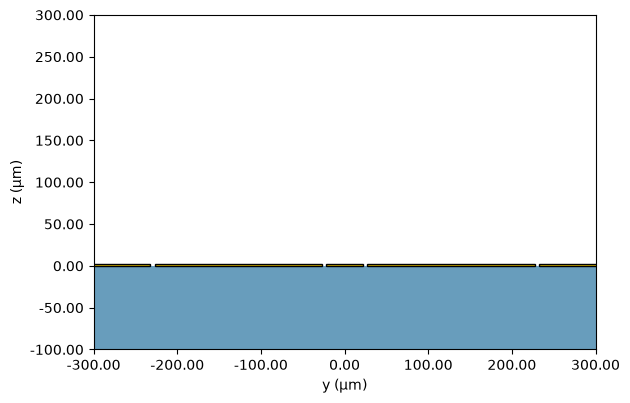

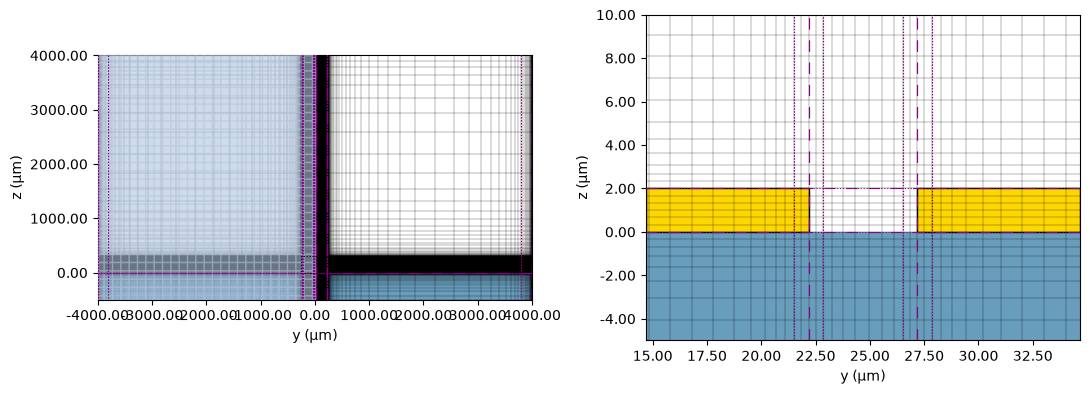

In [559]:
# Fused-silica substrate and perfectly conducting electrodes
silica = td.Medium(permittivity=silica_permittivity, name="Fused silica")

# One layout layer for the electrode metal
layers = {"METAL": pf.LayerSpec((1, 0), "Trap electrodes", "#b8a18b18", "\\")}

# Extrude the substrate under the whole chip, then the electrodes on top of it
extrusion_specs = [
    pf.ExtrusionSpec(pf.MaskSpec(), silica, (-substrate_thickness, 0)),
    pf.ExtrusionSpec(pf.MaskSpec((1, 0)), td.PEC, (0, metal_thickness)),
]

# Assemble the technology with an air background and make it the default
technology = pf.Technology(
    "Surface trap", "1.0", layers, extrusion_specs, {}, td.Medium()
)
pf.config.default_technology = technology


# Centre of each RF rail and inner edge of each outer ground along y (μm)
y_rf = center_width / 2 + gap + rf_width / 2
y_outer = center_width / 2 + 2 * gap + rf_width

# Half-width of the solver window and its height above the chip (μm)
half_width = 4000
top_height = 4000

# Width of each outer ground, reaching past the window edge (μm)
outer_width = half_width - y_outer + 100

# Cross-section of the five-wire trap
trap_spec = pf.PortSpec(
    description="Five-wire trap",
    width=2 * half_width,
    limits=(-substrate_thickness, top_height),
    num_modes=2,
    target_neff=1.5,
    path_profiles={
        "center": (center_width, 0, "METAL"),
        "rf0": (rf_width, y_rf, "METAL"),
        "rf1": (rf_width, -y_rf, "METAL"),
        "ground0": (outer_width, y_outer + outer_width / 2, "METAL"),
        "ground1": (outer_width, -y_outer - outer_width / 2, "METAL"),
    },
    voltage_path=[(y_outer, metal_thickness / 2), (y_rf, metal_thickness / 2)],
)

# Plot the cross-section around the trap
ax = pf.tidy3d_plot(trap_spec, frequency=f_rf)
ax.set_xlim(-300, 300)
ax.set_ylim(-100, 300)
ax.set_title("")
plt.show()


# Mode solver for the cross-section at the drive frequency
trap_solver = trap_spec.to_tidy3d([f_rf])

# Mesh the region of the ion and its escape point with 1 μm cells
ion_region = td.MeshOverrideStructure(
    geometry=td.Box.from_bounds((-1, -y_outer - 20, -10), (1, y_outer + 20, 300)),
    dl=(None, 1.0, 1.0),
)
grid_spec = trap_solver.simulation.grid_spec.updated_copy(
    override_structures=[ion_region]
)

# Solve only the half y > 0, using the mirror symmetry of the trap
simulation = trap_solver.simulation.updated_copy(
    symmetry=(0, 1, 0), grid_spec=grid_spec
)
trap_solver = trap_solver.updated_copy(simulation=simulation)

fig, ax = plt.subplots(1, 2, figsize=(11, 4), tight_layout=True)

# Whole solver window with its mesh
simulation.plot(x=0, ax=ax[0])
simulation.plot_grid(x=0, ax=ax[0])

# Close-up of the gap between the central ground and an RF rail
y_gap = center_width / 2 + gap / 2
simulation.plot(
    x=0, ax=ax[1], hlim=(y_gap - 2 * gap, y_gap + 2 * gap), vlim=(-gap, 2 * gap)
)
simulation.plot_grid(
    x=0, ax=ax[1], hlim=(y_gap - 2 * gap, y_gap + 2 * gap), vlim=(-gap, 2 * gap)
)
for a in ax:
    a.set_title("")
plt.show()

## SIMULATION (COSTS CREDITS)

In [560]:
# Solve for the two quasi-TEM modes of the electrode cross-section
trap_solver = pf.port_modes(trap_solver, task_name="Surface trap")

# Effective index of each mode
print("Effective indices:", trap_solver.data.n_eff.values.ravel())

Uploading task 'Surface trap…'
Starting task 'Surface trap': https://tidy3d.simulation.cloud/workbench?taskId=mo-5ef783f7-fbd7-45e4-8c2e-b7594cb29155
Progress: 100% 
Effective indices: [1.51550707 1.47807042]


## cool chart

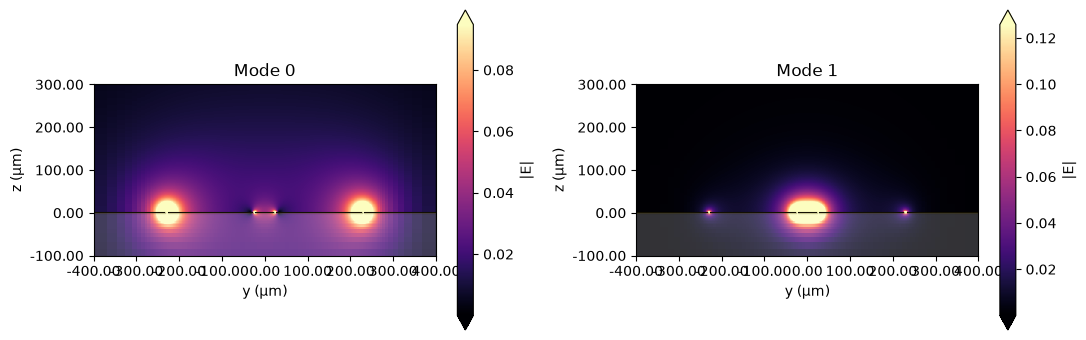

In [561]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), tight_layout=True)

# Electric field magnitude of each mode around the trap
for m in range(2):
    trap_solver.plot_field("E", "abs", mode_index=m, f=f_rf, ax=ax[m])
    ax[m].set_xlim(-400, 400)
    ax[m].set_ylim(-100, 300)
    ax[m].set_title(f"Mode {m}")
plt.show()

## final calculations:

In [562]:
# Mode fields on the cross-section at the drive frequency
fields = {
    component: trap_solver.data.field_components[component].isel(f=0).squeeze(drop=True)
    for component in ("Ey", "Ez")
}

# Line at mid-height of the electrodes, from inside the outer ground to the centre (μm)
y_line = np.linspace(y_outer + gap / 2, 0, 4001)

# Potential along the line in each mode, relative to the outer ground (V)
potentials = [
    -cumulative_trapezoid(
        fields["Ey"].isel(mode_index=m).interp(y=y_line, z=metal_thickness / 2).values,
        y_line,
        initial=0,
    )
    for m in range(2)
]

# Voltage of the RF rail (first row) and of the central ground (second row) in each mode
voltages = np.array(
    [
        [np.interp(y_rf, y_line[::-1], phi[::-1]) for phi in potentials],
        [phi[-1] for phi in potentials],
    ]
)

# Mode weights that put the RF rail at 1 V and the central ground at 0 V
weights = np.linalg.solve(voltages, [1.0, 0.0])

# Field of the trap per volt on the RF rails (V/μm)
e_unit = {
    component: sum(weights[m] * fields[component].isel(mode_index=m) for m in range(2))
    for component in fields
}
# Regular sampling grid around the trap (μm)
y_grid = np.arange(-150, 150.01, 0.5)
z_grid = np.arange(metal_thickness + 1, 350, 0.5)

# Squared field magnitude per volt on the grid, shape (y, z), in (V/μm)²
e2_unit = sum(
    np.abs(e_unit[component].interp(y=y_grid, z=z_grid).values) ** 2
    for component in e_unit
)

# Pseudopotential in J; the factor 1e12 converts (V/μm)² to (V/m)²
omega_rf = 2 * np.pi * f_rf
psi = ion_charge**2 * v_rf**2 * e2_unit * 1e12 / (4 * ion_mass * omega_rf**2)

# Pseudopotential in meV
psi_mev = psi / elementary_charge * 1e3

# Pseudopotential along the symmetry axis y = 0
i_axis = np.argmin(np.abs(y_grid))
psi_axis = psi[i_axis, :]

# Ion position: minimum of the pseudopotential on the axis
i_ion = np.argmin(psi_axis)
z_ion = z_grid[i_ion]
ion_height = z_ion - metal_thickness

# Escape point: maximum of the pseudopotential above the ion
i_saddle = i_ion + np.argmax(psi_axis[i_ion:])
trap_depth = psi_mev[i_axis, i_saddle] - psi_mev[i_axis, i_ion]

# Points within 3 μm of the ion for the parabola fits
fit_range = 3.0
near_z = np.abs(z_grid - z_ion) <= fit_range
near_y = np.abs(y_grid) <= fit_range

# Curvature of the pseudopotential along z and y (J/μm²)
curvature_z = 2 * np.polyfit(z_grid[near_z] - z_ion, psi_axis[near_z], 2)[0]
curvature_y = 2 * np.polyfit(y_grid[near_y], psi[near_y, i_ion], 2)[0]

# Secular angular frequencies; the factor 1e12 converts 1/μm² to 1/m²
omega_z = np.sqrt(curvature_z * 1e12 / ion_mass)
omega_y = np.sqrt(curvature_y * 1e12 / ion_mass)

# Radial secular frequency (Hz) and Mathieu parameter
f_secular = min(omega_y, omega_z) / (2 * np.pi)
q_mathieu = 2 * np.sqrt(2) * max(omega_y, omega_z) / omega_rf

print(f"Ion height above the electrodes: {ion_height:.1f} μm")
print(f"Secular frequency, lateral: {omega_y / 2 / np.pi / 1e6:.2f} MHz")
print(f"Secular frequency, vertical: {omega_z / 2 / np.pi / 1e6:.2f} MHz")
print(f"Mathieu parameter q: {q_mathieu:.8f}")
print(f"Trap depth: {trap_depth:.3f} meV")


Ion height above the electrodes: 75.0 μm
Secular frequency, lateral: 5.72 MHz
Secular frequency, vertical: 5.74 MHz
Mathieu parameter q: 0.40000000
Trap depth: 150.543 meV


## final cool chart


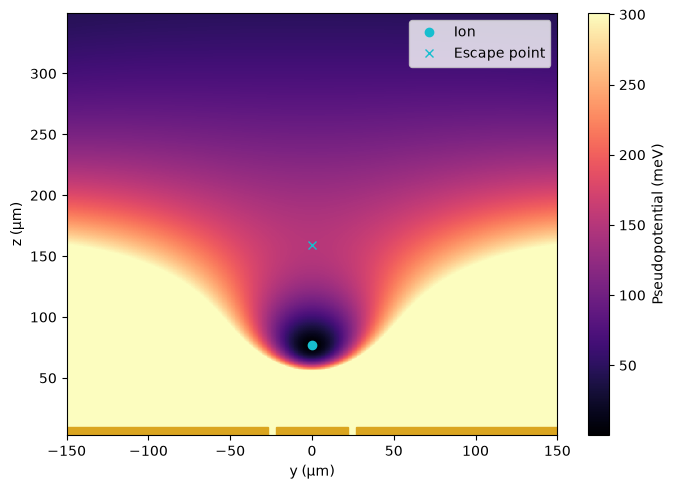

In [563]:
fig, ax = plt.subplots(figsize=(7, 5), tight_layout=True)

# Pseudopotential map in meV
mesh = ax.pcolormesh(
    y_grid, z_grid, psi_mev.T, vmax=2 * trap_depth, cmap="magma", shading="auto"
)
fig.colorbar(mesh, ax=ax, label="Pseudopotential (meV)")

# Ion position and escape point
ax.plot(0, z_ion, "o", color="tab:cyan", label="Ion")
ax.plot(0, z_grid[i_saddle], "x", color="tab:cyan", label="Escape point")

# Electrode positions along the bottom edge
for y0, y1 in [
    (-center_width / 2, center_width / 2),
    (center_width / 2 + gap, center_width / 2 + gap + rf_width),
    (-center_width / 2 - gap - rf_width, -center_width / 2 - gap),
]:
    ax.axvspan(y0, y1, ymax=0.02, color="goldenrod")
ax.set_xlabel("y (μm)")
ax.set_ylabel("z (μm)")
ax.set_xlim(y_grid[0], y_grid[-1])
ax.legend(loc="upper right")
plt.show()

Score calulation:

In [564]:
def trap_score(ion_height, f_secular, q_mathieu, v_rf, min_feature, trap_depth):
    # Pass or fail for every constraint of the challenge
    checks = {
        "Ion height 50 to 100 μm": 50 <= ion_height <= 100,
        "Radial secular frequency at least 1 MHz": f_secular >= 1e6,
        "Mathieu parameter q at most 0.4": q_mathieu <= 0.4,
        "Peak RF voltage at most 100 V": v_rf <= 100,
        "Minimum electrode feature or gap at least 5 μm": min_feature >= 5,
    }

    # Print the outcome of each check
    for name, passed in checks.items():
        print(f"{'PASS' if passed else 'FAIL'}  {name}")

    # Trap depth if every constraint passes, zero otherwise
    return trap_depth if all(checks.values()) else 0.0


# Smallest drawn feature or gap of the layout (μm)
min_feature = min(center_width, rf_width, gap)

# Score of the current design
score = trap_score(ion_height, f_secular, q_mathieu, v_rf, min_feature, trap_depth)
print(f"\nScore: {score:.1f} meV at {v_rf:.0f} V")
print("meV per voltage: " + str(score/v_rf ))

PASS  Ion height 50 to 100 μm
PASS  Radial secular frequency at least 1 MHz
PASS  Mathieu parameter q at most 0.4
PASS  Peak RF voltage at most 100 V
PASS  Minimum electrode feature or gap at least 5 μm

Score: 150.5 meV at 100 V
meV per voltage: 1.5054264791034364
